# Faraday depth tomography: active maintainer review

## 1. Problem
Reconstruct complex polarized emission along one line of sight from incomplete positive wavelength-squared sampling. This observation is **the complete distributed simulated288-channel spectrum**, not a real sky measurement. The output is a selected resolution-limited method result, not a unique physical distance profile. The source's ordinary synthesis and single-threshold CLEAN stages are selected; optional QU fitting, windowed deeper CLEAN, and super resolution are outside this scope.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,hashlib,subprocess
import numpy as np
import matplotlib.pyplot as plt
TASK=Path.cwd()
if TASK.name=='notebooks': TASK=TASK.parent
assert (TASK/'data/raw_data.npz').is_file()
os.chdir(TASK)
if str(TASK) not in sys.path:sys.path.insert(0,str(TASK))
from src.preprocessing import load_observations
from src.main import run
from src.solvers import PHI
from src.visualization import plot_spectra,plot_observation,plot_metrics,relative_l2
print('Actual kernel:',sys.executable)
print('NumPy:',np.__version__)
print('Observation SHA256:',hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest())


Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy: 2.4.6
Observation SHA256: 669b32e0e7be055a983bec65e7167453a5e31d61c39dd70102643c8ffb7e0d31


## 2. Data
All288 increasing frequencies, signed complexQ+iU fluxes, and independent real-component noise standard deviations are public. There is no normalization by a hidden target or by StokesI. The entire original channel sequence is retained with float64 precision. No new noise/object has been generated. Source capture provenance and failed real-data access probes remain in the maintainer archive.


In [2]:
observations=load_observations()
for key,value in observations.items():print(key,value.shape,value.dtype)
print('Frequency interval Hz:',observations['frequency'][[0,-1]])
print('Per Q/U component noise Jy/beam:',np.unique(observations['noise']))


frequency (288,) float64
polarization (288,) complex128
noise (288,) float64
Frequency interval Hz: [8.000e+08 1.088e+09]
Per Q/U component noise Jy/beam: [0.1]


## 3. Physics
Let $P_k=Q_k+iU_k$, $t_k=(c/\nu_k)^2$ m², $w_k=\sigma_k^{-2}$ and $t_0=\sum w_kt_k/\sum w_k$. A complex per-bin polarized flux $C_j$ in Jy/beam at depth $\phi_j$ rad/m² predicts

\[
P_k=\sum_jC_j\exp[2i\phi_j(t_k-t_0)]+\epsilon_k.
\]

The forward sign is positive and its complex Euclidean adjoint uses the negative sign. No depth-bin width factor is inserted. The normalized inverse Fourier sum produces the dirty spectrum. Its finite-coverage response is $R(\psi)=\sum_kw_k\exp[-2i\psi(t_k-t_0)]/\sum_kw_k$. A unit component generates this response shifted to its depth. The nonzero spectral index in the supplied sample is not corrected by the selected absolute-flux method and can leave model residual structure; it is not evidence of a separate physical emitting layer.


## 4. Method
Initialize the component spectrum and restoring accumulator to zero, and the residual to the dirty spectrum. At each step choose the largest absolute complex residual, transfer fraction0.1 to that bin, and subtract the same complex component times a shifted full response. Stop at three transformed-noise standard deviations or1000 updates. The transformed per-component noise is $\sqrt{\sum w_k^2\sigma_k^2}/\sum w_k$.

Restore each selected component with a unit-peak Gaussian of source-prescribed FWHM $W=3.8/(\max t-\min t)$, then add the remaining dirty residual. The optional second masked loop is disabled through the original public window=None option, rather than silently dropping the source's low-level default-window0 behavior. No Gaussian unit-area rescaling, phase fitting or shifting is used during evaluation.

The next cell **actively reconstructs all channels with cleaned modules** and writes a fresh submission. No archived output substitutes for this step.


In [3]:
start=time.perf_counter()
submission,details=run()
fresh_wall=time.perf_counter()-start
print('Fresh full pipeline seconds:',fresh_wall)
print('CLEAN updates:',details['iterations'],'cutoff:',details['cutoff'],'FWHM:',details['width'])
command=[sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json']
completed=subprocess.run(command,check=True,capture_output=True,text=True)
report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2))
assert report['passed']


Fresh full pipeline seconds: 0.011706500081345439
CLEAN updates: 50 cutoff: 0.01767766952966369 FWHM: 58.90951914103005
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_relative_l2": 4.244245764528543e-13,
    "components_relative_l2": 1.174829573676006e-13,
    "forward_reduced_chi2": 1.0996341269453034
  },
  "thresholds": {
    "reconstruction_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "components_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "forward_reduced_chi2": {
      "comparison": "<=",
      "boundary": 1.209597539639874
    }
  },
  "errors": []
}


## 5. Results
The independently reproduced original arrays are loaded only after the fresh pipeline. Original measurements and fresh measurements are labeled separately. The comparisons include complete dirty/restored spectra, complexphase information, sparse components, response sidelobes, channelQ/U, forward residuals, and measured metric boundaries. Lower residual or closer method agreement does not demonstrate unique physical truth.


Independent original captured runtime seconds: 0.028315699892118573
Original/fresh complex relative errors: {'reconstruction': 4.244245764528543e-13, 'components': 1.174829573676006e-13}


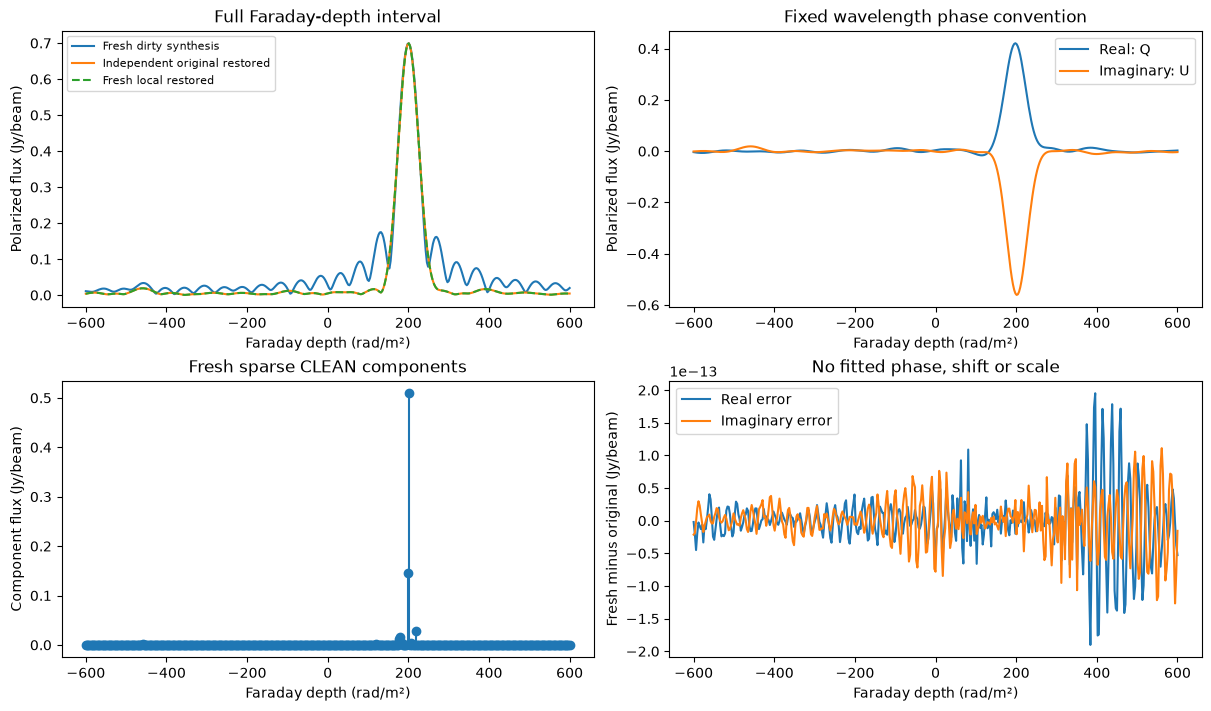

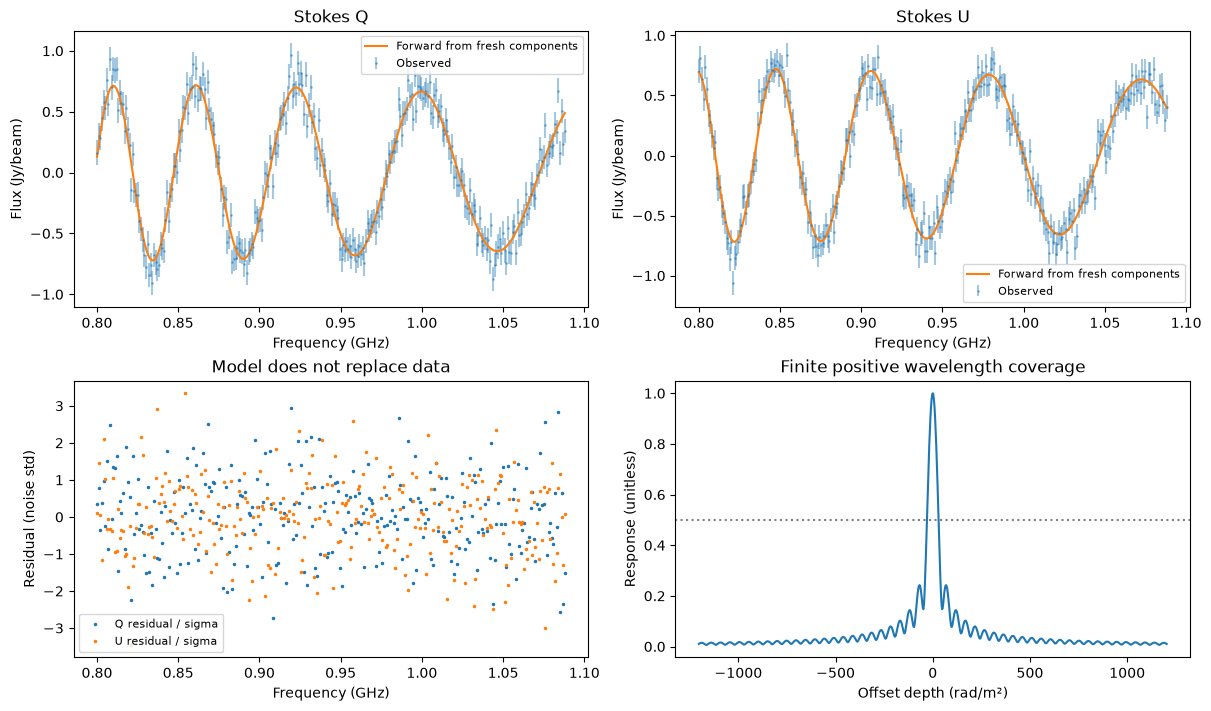

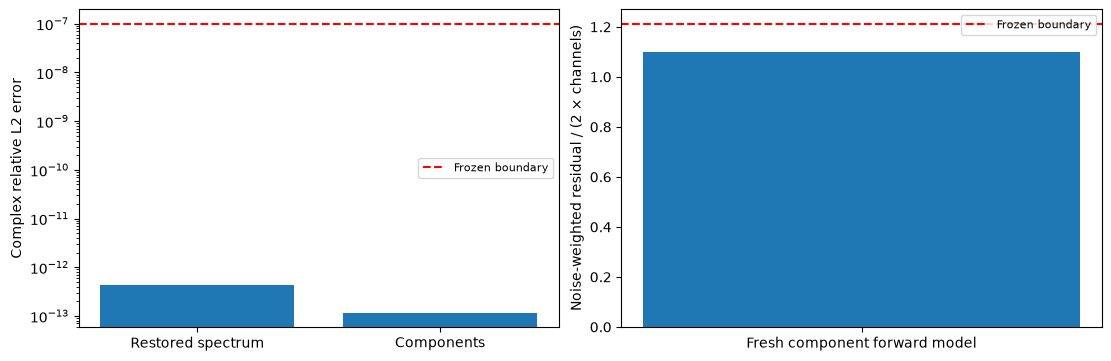

In [4]:
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
with np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:
    print('Independent original captured runtime seconds:',float(f['runtime_seconds']))
print('Original/fresh complex relative errors:',{k:relative_l2(submission[k],reference[k]) for k in submission})
plot_spectra(submission,details,reference);plt.show()
plot_observation(details);plt.show()
plot_metrics(report);plt.show()
np.savez_compressed('notebooks/reference_outputs/fresh_measurements.npz',runtime_seconds=np.array(fresh_wall),iterations=np.array(details['iterations']),metric_values=np.array(list(report['metrics'].values())))


## 6. Conclusion
The fresh full-channel inverse is compared against an independent original execution and passed the frozen complex-spectrum/component and observation-consistency checks. Numerical parity is supported separately by complete-stage fixtures, while adjoint, thin-screen and residual-operator checks test physical signs and scale. The broad finite-wavelength response limits depth resolution. Source intensity varies with frequency and the selected unnormalized model does not remove that variation. This notebook establishes a verified method reproduction on simulated observations, without claiming real-sky validation, unique physical depth structure, or completion of unselected algorithms from the paper.
